In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/thedevastator/books-sales-and-ratings/Books_Data_Clean.csv


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv('/kaggle/input/datasets/thedevastator/books-sales-and-ratings/Books_Data_Clean.csv')
df.head()
df.shape

(1070, 15)

In [6]:
df.describe()

,index,Publishing Year,Book_average_rating,Book_ratings_count,gross sales,publisher revenue,sale price,sales rank,units sold
count,1070.000000,1069.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000
mean,534.500000,1971.377923,4.007000,94909.913084,1856.622944,843.281030,4.869561,611.652336,9676.980374
std,309.026698,185.080257,0.247244,31513.242518,3936.924240,2257.596743,3.559919,369.849830,15370.571306
min,0.000000,-560.000000,2.970000,27308.000000,104.940000,0.000000,0.990000,1.000000,106.000000
25%,267.250000,1985.000000,3.850000,70398.000000,372.465000,0.000000,1.990000,287.500000,551.250000
50%,534.500000,2003.000000,4.015000,89309.000000,809.745000,273.078000,3.990000,595.500000,3924.000000
75%,801.750000,2010.000000,4.170000,113906.500000,1487.957500,721.180500,6.990000,932.500000,5312.250000
max,1069.000000,2016.000000,4.770000,206792.000000,47795.000000,28677.000000,33.860000,1273.000000,61560.000000


#fixing negative publishing year

In [7]:
df = df[df['Publishing Year'] > 1900]
df.shape

(1009, 15)

CHECKING FOR NULL VALUES

In [8]:
df.isna().sum()

index                   0
Publishing Year         0
Book Name              21
Author                  0
language_code          49
Author_Rating           0
Book_average_rating     0
Book_ratings_count      0
genre                   0
gross sales             0
publisher revenue       0
sale price              0
sales rank              0
Publisher               0
units sold              0
dtype: int64

DROPING NA VALUES ON BOOK NAME

In [9]:
df.dropna(subset = 'Book Name',inplace = True)
df
df.shape

(988, 15)

CHECKING FOR DUPLICATE VALUES

In [10]:
df.duplicated().sum()

np.int64(0)

CHECK FOR UNIQUE VALUES

In [11]:
df.nunique()

index                  988
Publishing Year        101
Book Name              987
Author                 669
language_code            8
Author_Rating            4
Book_average_rating    133
Book_ratings_count     983
genre                    4
gross sales            774
publisher revenue      570
sale price             143
sales rank             818
Publisher                9
units sold             470
dtype: int64

BOOKS PUBLISHED DISTRIBUTION

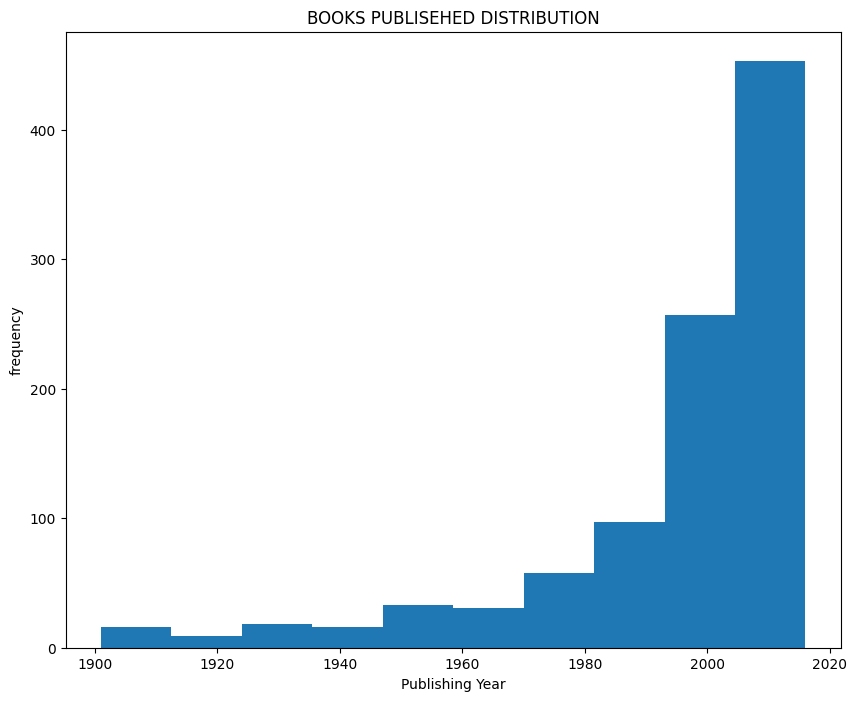

In [12]:
plt.figure(figsize = (10,8))
plt.hist(df['Publishing Year'])
plt.xlabel('Publishing Year')
plt.ylabel('frequency')
plt.title('BOOKS PUBLISEHED DISTRIBUTION')
plt.show()

BOOKS PUBLISHED ON BASIS OF GENRE

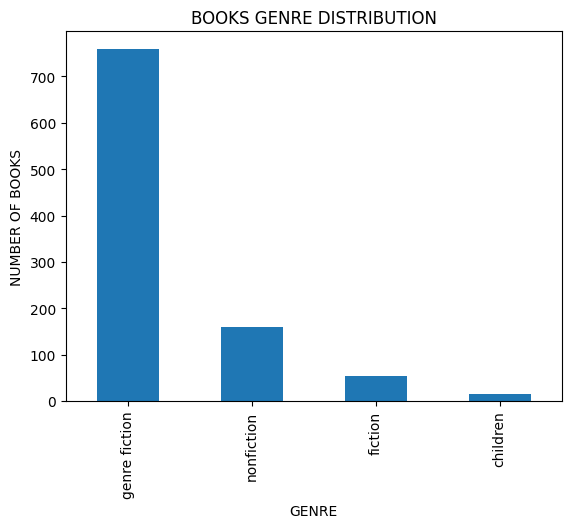

In [13]:
df['genre'].value_counts().plot(kind = 'bar')
plt.xlabel('GENRE')
plt.ylabel('NUMBER OF BOOKS')
plt.title('BOOKS GENRE DISTRIBUTION')
plt.show()

GROUP BY TOP 10 AUTHOR ON BASIS OF AVG BOOK RATING

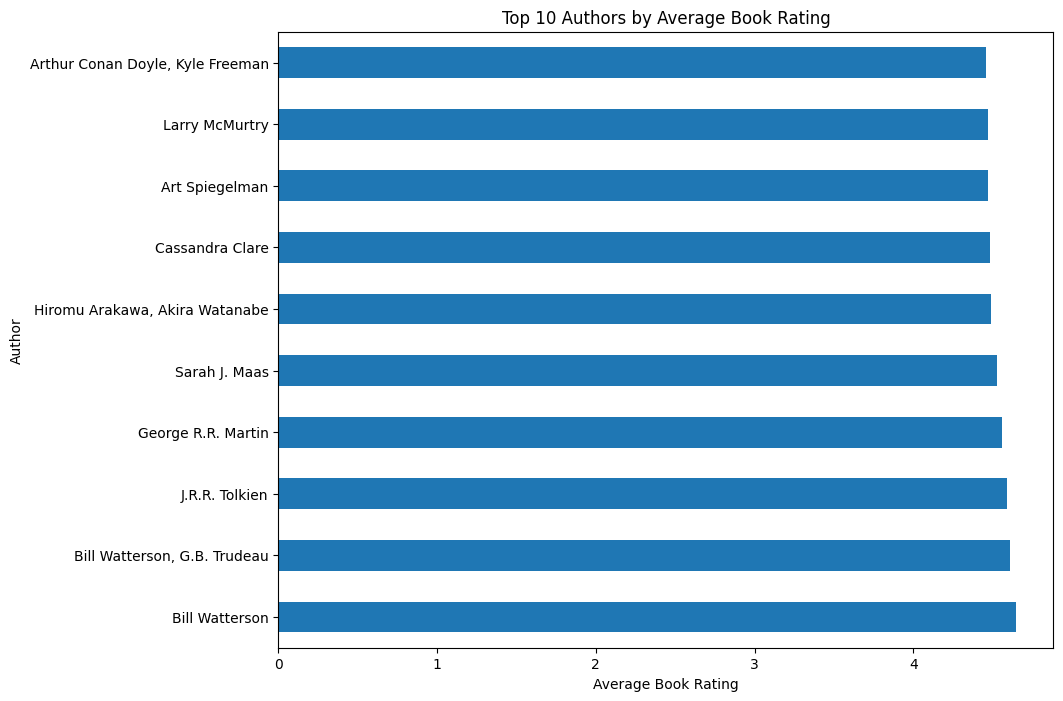

In [14]:
author_rating = df.groupby('Author')['Book_average_rating'].mean()

top_10 = author_rating.sort_values(ascending=False).head(10)

top_10.plot(kind='barh', figsize=(10, 8))

plt.xlabel('Average Book Rating')
plt.ylabel('Author')
plt.title('Top 10 Authors by Average Book Rating')
plt.show()

SALES AND UNITS SOLD SCATTERPLOT

Text(0.5, 1.0, 'sales plot')

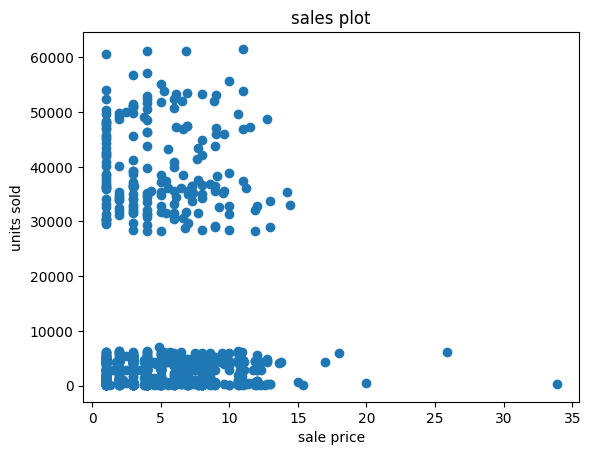

In [15]:
plt.scatter(df['sale price'],df['units sold'])
plt.xlabel('sale price')
plt.ylabel('units sold')
plt.title('sales plot')

PIE CHART OF BOOK LANGUAGES

In [16]:
language_count = df['language_code'].value_counts()

Text(0.5, 1.0, 'book language composition')

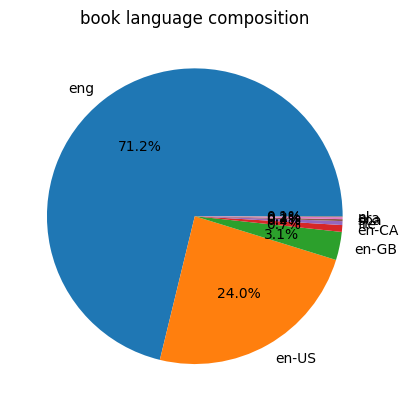

In [21]:
plt.pie(language_count,labels = language_count.index,autopct='%1.1f%%')
plt.title('book language composition')

REVENUE GENEREATED BY PUBLISHER

In [22]:
df.columns

Index(['index', 'Publishing Year', 'Book Name', 'Author', 'language_code',
       'Author_Rating', 'Book_average_rating', 'Book_ratings_count', 'genre',
       'gross sales', 'publisher revenue', 'sale price', 'sales rank',
       'Publisher ', 'units sold'],
      dtype='object')

In [27]:
df.groupby('Publisher ')['publisher revenue'].sum().sort_values(ascending = False)


Publisher 
Penguin Group (USA) LLC                 191581.104
Random House LLC                        174956.244
Amazon Digital Services,  Inc.          141767.772
HarperCollins Publishers                121769.814
Hachette Book Group                     107410.968
Simon and Schuster Digital Sales Inc     46858.206
Macmillan                                31249.830
HarperCollins Publishing                  2830.806
HarperCollins Christian Publishing        2135.670
Name: publisher revenue, dtype: float64

BOOK RATINGS

In [30]:
df.groupby('Author_Rating')['Book_ratings_count'].mean().sort_values(ascending = False)

Author_Rating
Intermediate    101400.272569
Famous           98295.250000
Novice           87318.464286
Excellent        83804.800595
Name: Book_ratings_count, dtype: float64

In [35]:
df.groupby('Author_Rating')['Book_ratings_count'].max()

Author_Rating
Excellent       167848
Famous          206792
Intermediate    199872
Novice          155903
Name: Book_ratings_count, dtype: int64

In [36]:
df.groupby('Author_Rating')['Book_ratings_count'].min()

Author_Rating
Excellent       32626
Famous          54977
Intermediate    27308
Novice          42339
Name: Book_ratings_count, dtype: int64

TOTAL LANGUAGE CODES

In [31]:
df.groupby('language_code').size().sort_values(ascending = False)


language_code
eng      670
en-US    226
en-GB     29
en-CA      7
fre        4
ara        2
spa        2
nl         1
dtype: int64

Text(0.5, 1.0, 'scatter plot of book average rating vs book rating count')

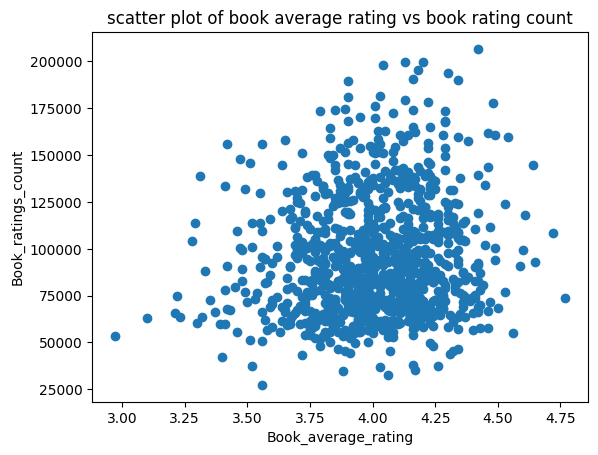

In [41]:
plt.scatter(df['Book_average_rating'],df['Book_ratings_count'])
plt.xlabel('Book_average_rating')
plt.ylabel('Book_ratings_count')
plt.title('scatter plot of book average rating vs book rating count')

author sales analysis

In [44]:
total_gross_sales_of_author = df.groupby('Author')['gross sales'].sum()


In [45]:
total_gross_sales_of_author.sort_values(ascending = False)

Author
Harper Lee              47795.00
Stephen King            43322.65
David Sedaris           42323.41
Charlaine Harris        39453.08
Laini Taylor            38278.41
                          ...   
Nathaniel Philbrick       107.91
Frank Warren              107.91
Walter M. Miller Jr.      106.92
Michael Shaara            105.93
Blake Crouch              105.93
Name: gross sales, Length: 669, dtype: float64

Text(0.5, 1.0, 'TOP 10 AUTHOR VS SALES ANALYSIS')

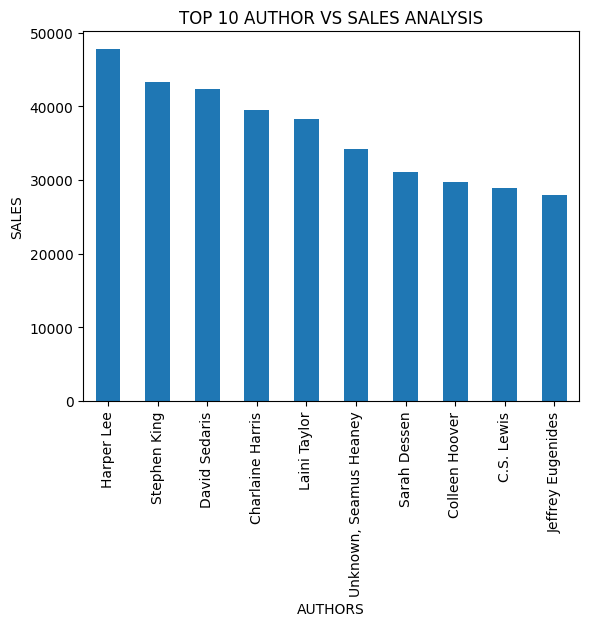

In [49]:
total_gross_sales_of_author.sort_values(ascending = False).head(10).plot(kind = 'bar')
plt.xlabel('AUTHORS')
plt.ylabel('SALES')
plt.title('TOP 10 AUTHOR VS SALES ANALYSIS')

In [ ]:
AUTHOR SALES ANALYSIS

Text(0.5, 1.0, 'BOS PLOT FOR UNITS SOLD FOR EACH AUTHOR')

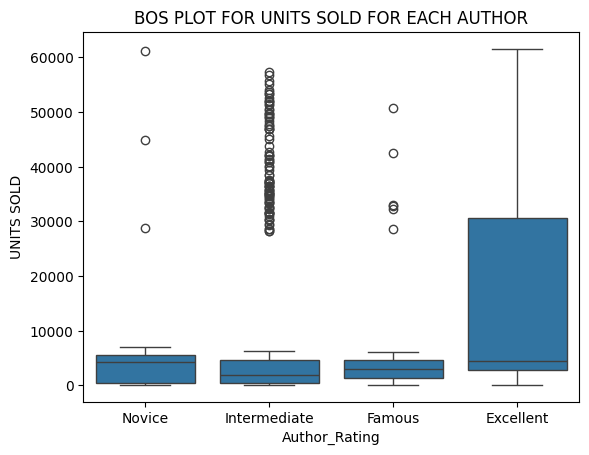

In [53]:
sns.boxplot(x='Author_Rating',y = 'units sold',data = df)
plt.ylabel('UNITS SOLD')
plt.title('BOS PLOT FOR UNITS SOLD FOR EACH AUTHOR')

LINE CHART ANALYSIS

Text(0.5, 1.0, 'Total Units Sold Over The Years')

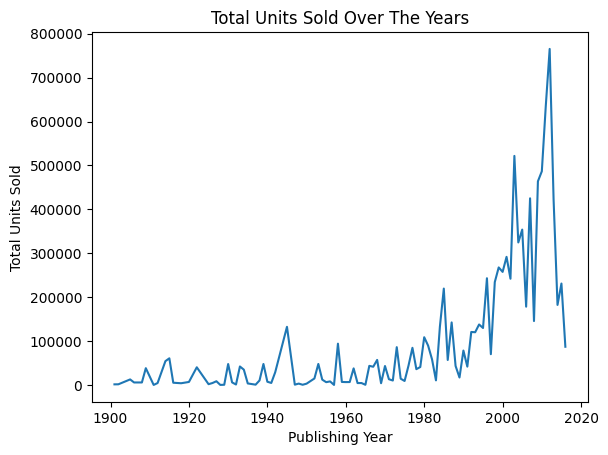

In [54]:
df.groupby('Publishing Year')['units sold'].sum().plot(kind = 'line')
plt.xlabel('Publishing Year')
plt.ylabel('Total Units Sold')
plt.title('Total Units Sold Over The Years')